# A6 - Dự đoán hành vi tiếp theo của khách hàng bằng RNN (PyTorch)

**Dataset:** `events.csv` - Retailrocket E-commerce Dataset  
**Framework:** PyTorch  
**Mô hình:** `Embedding + RNN + Linear`  
**Bài toán:** dùng **5 hành vi gần nhất của một visitor** để dự đoán **hành vi tiếp theo**.

Ba hành vi:
- `view`
- `addtocart`
- `transaction`

Đây là bài toán **Many-to-One Classification**.

Quy trình:
1. Load Data
2. Data Understanding
3. Cleaning
4. Visualization / EDA
5. Phân tích chuỗi hành vi
6. Encoding
7. Create Sequence theo từng visitor
8. Giới hạn dữ liệu để demo
9. Train / Validation / Test theo thời gian
10. Xử lý mất cân bằng
11. Dataset / DataLoader
12. Build RNN PyTorch
13. Train
14. Training / Validation curves
15. Predict
16. Evaluate
17. Confusion Matrix + Classification Report
18. Majority Baseline
19. Visualization
20. Demo dự đoán
21. Lưu model / kết quả
22. Kết luận

> **Quan trọng:** Không tạo sequence xuyên qua hai `visitorid` khác nhau.

**Bản nộp độc lập:** toàn bộ hàm xử lý dữ liệu, định nghĩa mô hình, huấn luyện
và kiểm tra tải lại đều nằm trong notebook. Không cần các file `.py` của dự án.
Đặt CSV tương ứng cạnh notebook, chọn kernel đã cài thư viện và Restart & Run All.
Chọn checkpoint/cấu hình bằng Validation; Test chỉ dùng để báo cáo cuối cùng.

## 0. Import thư viện

In [1]:
# Nếu cần: %pip install numpy pandas matplotlib scikit-learn torch

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set before importing a framework; helps deterministic CUDA execution.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
SEED = int(os.environ.get("RNN_SEED", "42"))
np.random.seed(SEED)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", DEVICE, "| Seed:", SEED)

PyTorch: 2.14.0+cpu | Device: cpu | Seed: 42


## 1. Load Data

In [2]:
# Hỗ trợ CSV cạnh notebook hoặc cấu trúc data/ + notebooks/.
candidates = [Path.cwd() / "events.csv",
              Path.cwd() / "data" / "events.csv",
              Path.cwd().parent / "data" / "events.csv"]
DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Đặt events.csv cạnh notebook hoặc trong thư mục data/.")
PROJECT_ROOT = DATA_PATH.parent.parent if DATA_PATH.parent.name == "data" else DATA_PATH.parent
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_raw = pd.read_csv(DATA_PATH)
required_columns = ['timestamp', 'visitorid', 'itemid', 'event']
missing = set(required_columns) - set(df_raw.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
print("Data:", DATA_PATH)
print("Results:", RESULTS_DIR)
print("Shape:", df_raw.shape)
display(df_raw.head())

Data: D:\A06\data\events.csv
Results: D:\A06\results
Shape: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


## 2. Data Understanding

In [3]:
print("5 dòng đầu:")
display(df_raw.head())

print("\n5 dòng cuối:")
display(df_raw.tail())

print("\nShape:", df_raw.shape)
print("\nColumns:", df_raw.columns.tolist())

print("\nInfo:")
df_raw.info()

5 dòng đầu:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



5 dòng cuối:


,timestamp,visitorid,event,itemid,transactionid
2756096,1438398785939,591435,view,261427,NaN
2756097,1438399813142,762376,view,115946,NaN
2756098,1438397820527,1251746,view,78144,NaN
2756099,1438398530703,1184451,view,283392,NaN
2756100,1438400163914,199536,view,152913,NaN



Shape: (2756101, 5)

Columns: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [4]:
print("Thống kê mô tả:")
display(df_raw.describe(include="all"))

Thống kê mô tả:


,timestamp,visitorid,event,itemid,transactionid
count,2.756101e+06,2.756101e+06,2756101,2.756101e+06,22457.000000
unique,NaN,NaN,3,NaN,NaN
top,NaN,NaN,view,NaN,NaN
freq,NaN,NaN,2664312,NaN,NaN
mean,1.436424e+12,7.019229e+05,NaN,2.349225e+05,8826.497796
std,3.366312e+09,4.056875e+05,NaN,1.341954e+05,5098.996290
min,1.430622e+12,0.000000e+00,NaN,3.000000e+00,0.000000
25%,1.433478e+12,3.505660e+05,NaN,1.181200e+05,4411.000000
50%,1.436453e+12,7.020600e+05,NaN,2.360670e+05,8813.000000
75%,1.439225e+12,1.053437e+06,NaN,3.507150e+05,13224.000000


### Ý nghĩa cột
- `timestamp`: thời điểm xảy ra event.
- `visitorid`: mã khách truy cập.
- `event`: `view`, `addtocart`, `transaction`.
- `itemid`: mã sản phẩm.
- `transactionid`: chỉ có ý nghĩa khi có giao dịch.

Trong bài này, ta tập trung vào **chuỗi `event` theo thời gian của từng visitor**.

## 3. Cleaning

In [5]:
df = df_raw.copy()

print("Missing values:")
display(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

df["event"] = (
    df["event"]
    .astype(str)
    .str.strip()
    .str.lower()
)

valid_events = ["view", "addtocart", "transaction"]

df = df[
    df["datetime"].notna()
    & df["visitorid"].notna()
    & df["itemid"].notna()
    & df["event"].isin(valid_events)
].copy()

df["visitorid"] = pd.to_numeric(df["visitorid"], errors="coerce")
df["itemid"] = pd.to_numeric(df["itemid"], errors="coerce")

df = df.dropna(subset=["visitorid", "itemid"]).copy()

df["visitorid"] = df["visitorid"].astype("int64")
df["itemid"] = df["itemid"].astype("int64")

df = (
    df.sort_values(["visitorid", "datetime", "timestamp"])
      .reset_index(drop=True)
)

print("Shape sau cleaning:", df.shape)
print("Khoảng thời gian:", df["datetime"].min(), "->", df["datetime"].max())
print("\nEvent counts:")
print(df["event"].value_counts())

display(df.head())

Missing values:


timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64


Duplicate rows: 460
Shape sau cleaning: (2755641, 6)
Khoảng thời gian: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000

Event counts:
event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1442004589439,0,view,285930,NaN,2015-09-11 20:49:49.439
1,1442004759591,0,view,357564,NaN,2015-09-11 20:52:39.591
2,1442004917175,0,view,67045,NaN,2015-09-11 20:55:17.175
3,1439487966444,1,view,72028,NaN,2015-08-13 17:46:06.444
4,1438969904567,2,view,325215,NaN,2015-08-07 17:51:44.567


`transactionid` thiếu ở các event không phải giao dịch là **bình thường**, nên không cần điền.

## 4. Visualization / EDA

,count
event,
view,2664218
addtocart,68966
transaction,22457


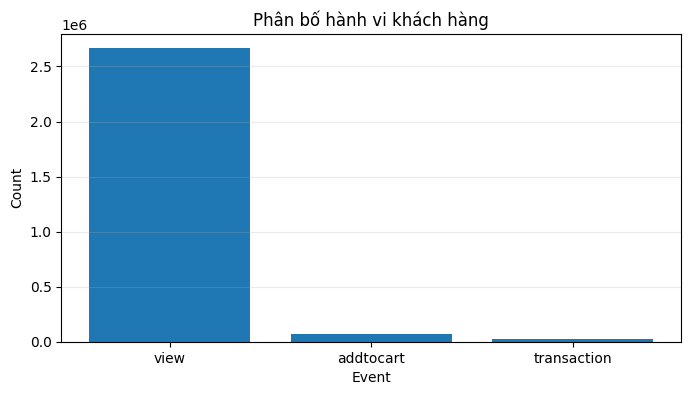

In [6]:
event_counts = (
    df["event"]
    .value_counts()
    .reindex(["view", "addtocart", "transaction"])
    .fillna(0)
)

display(event_counts.to_frame("count"))

plt.figure(figsize=(8, 4))
plt.bar(event_counts.index, event_counts.values)
plt.title("Phân bố hành vi khách hàng")
plt.xlabel("Event")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.25)
plt.show()

,percent
event,
view,96.68
addtocart,2.50
transaction,0.81


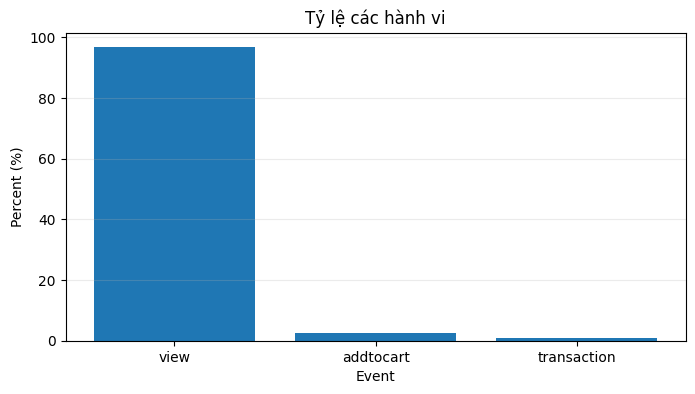

In [7]:
event_percent = event_counts / event_counts.sum() * 100

display(event_percent.round(2).to_frame("percent"))

plt.figure(figsize=(8, 4))
plt.bar(event_percent.index, event_percent.values)
plt.title("Tỷ lệ các hành vi")
plt.xlabel("Event")
plt.ylabel("Percent (%)")
plt.grid(axis="y", alpha=0.25)
plt.show()

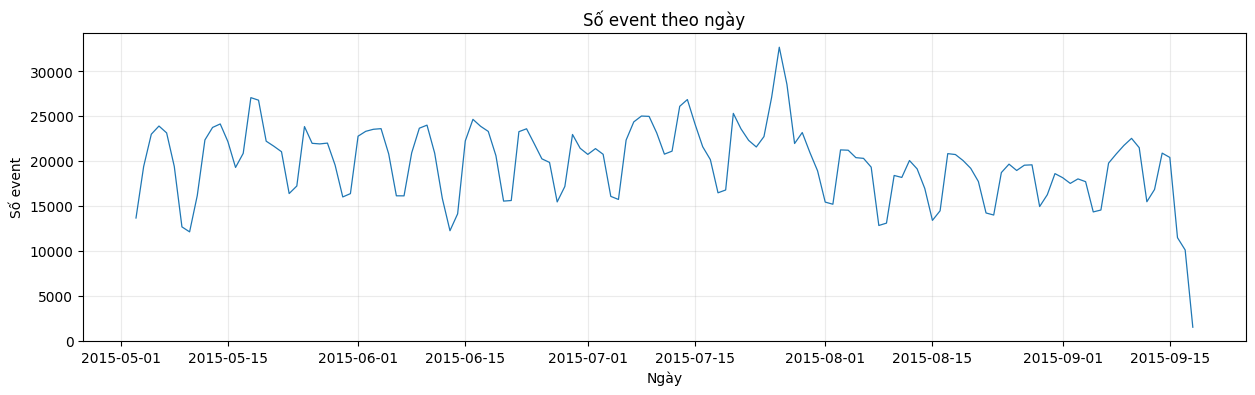

In [8]:
events_per_day = (
    df.set_index("datetime")
      .resample("D")
      .size()
)

plt.figure(figsize=(15, 4))
plt.plot(events_per_day.index, events_per_day.values, linewidth=0.9)
plt.title("Số event theo ngày")
plt.xlabel("Ngày")
plt.ylabel("Số event")
plt.grid(alpha=0.25)
plt.show()

Số visitor: 1407580


,events_per_visitor
count,1.407580e+06
mean,1.957715e+00
std,1.257981e+01
min,1.000000e+00
50%,1.000000e+00
75%,2.000000e+00
90%,3.000000e+00
95%,5.000000e+00
99%,1.300000e+01
max,7.757000e+03


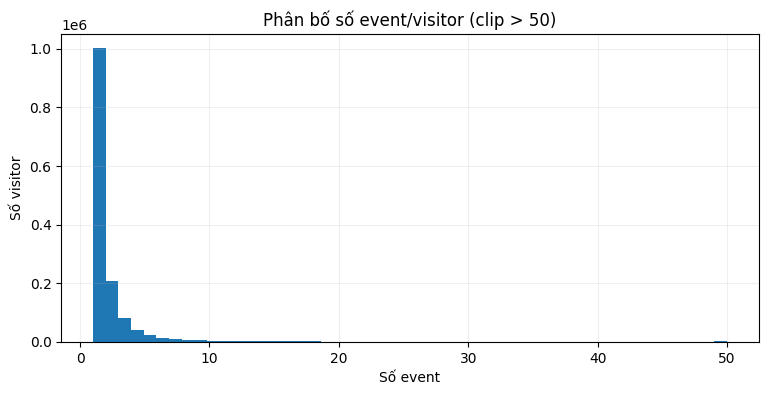

In [9]:
events_per_visitor = (
    df.groupby("visitorid")
      .size()
      .sort_values(ascending=False)
)

print("Số visitor:", events_per_visitor.shape[0])

display(
    events_per_visitor.describe(
        percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
    ).to_frame("events_per_visitor")
)

plt.figure(figsize=(9, 4))
plt.hist(np.clip(events_per_visitor.values, 1, 50), bins=50)
plt.title("Phân bố số event/visitor (clip > 50)")
plt.xlabel("Số event")
plt.ylabel("Số visitor")
plt.grid(alpha=0.2)
plt.show()

,unique_visitors
event,
view,1404179
addtocart,37722
transaction,11719


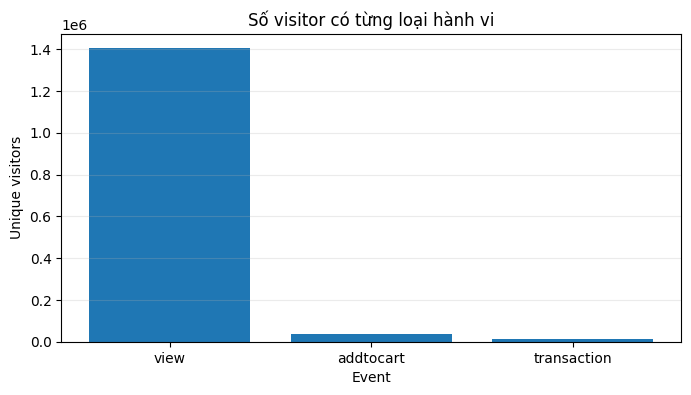

In [10]:
visitors_by_event = (
    df.groupby("event")["visitorid"]
      .nunique()
      .reindex(["view", "addtocart", "transaction"])
)

display(visitors_by_event.to_frame("unique_visitors"))

plt.figure(figsize=(8, 4))
plt.bar(visitors_by_event.index, visitors_by_event.values)
plt.title("Số visitor có từng loại hành vi")
plt.xlabel("Event")
plt.ylabel("Unique visitors")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 5. Phân tích chuỗi hành vi

In [11]:
SEQ_LENGTH = 5
MIN_EVENTS_PER_VISITOR = SEQ_LENGTH + 1

visitor_counts = df.groupby("visitorid").size()

eligible_visitors = visitor_counts[
    visitor_counts >= MIN_EVENTS_PER_VISITOR
].index

behavior_df = df[
    df["visitorid"].isin(eligible_visitors)
].copy()

print("Tổng visitor:", df["visitorid"].nunique())
print("Visitor đủ điều kiện:", len(eligible_visitors))
print("Số event dùng để tạo sequence:", len(behavior_df))

Tổng visitor: 1407580
Visitor đủ điều kiện: 58627
Số event dùng để tạo sequence: 833262


In [12]:
example_visitor = (
    behavior_df.groupby("visitorid")
               .size()
               .sort_values(ascending=False)
               .index[0]
)

print("Example visitor:", example_visitor)

display(
    behavior_df[
        behavior_df["visitorid"] == example_visitor
    ][["datetime", "event", "itemid"]].head(20)
)

Example visitor: 1150086


,datetime,event,itemid
2255072,2015-06-11 14:55:17.389,view,133542
2255073,2015-06-11 15:15:35.608,view,167873
2255074,2015-06-11 15:20:06.651,view,231726
2255075,2015-06-11 15:24:48.806,view,427777
2255076,2015-06-11 15:25:32.155,view,398115
2255077,2015-06-11 15:26:43.191,addtocart,398115
2255078,2015-06-11 15:28:45.614,transaction,398115
2255079,2015-06-11 15:29:03.539,view,398115
2255080,2015-06-11 15:32:07.711,view,203425
2255081,2015-06-11 15:34:51.672,view,458489


## 6. Encoding

In [13]:
EVENT_TO_ID = {
    "view": 0,
    "addtocart": 1,
    "transaction": 2
}

ID_TO_EVENT = {v: k for k, v in EVENT_TO_ID.items()}

behavior_df["event_id"] = (
    behavior_df["event"]
    .map(EVENT_TO_ID)
    .astype("int32")
)

print(EVENT_TO_ID)

display(
    behavior_df[
        ["visitorid", "datetime", "event", "event_id"]
    ].head()
)

{'view': 0, 'addtocart': 1, 'transaction': 2}


,visitorid,datetime,event,event_id
4,2,2015-08-07 17:51:44.567,view,0
5,2,2015-08-07 17:53:33.790,view,0
6,2,2015-08-07 17:56:52.664,view,0
7,2,2015-08-07 18:01:08.920,view,0
8,2,2015-08-07 18:08:25.669,view,0


Các mã `0, 1, 2` chỉ là **ID của lớp**, không biểu diễn khoảng cách số học.  
Lớp `Embedding` sẽ học vector biểu diễn cho từng hành vi.

## 7. Create Sequences theo từng visitor

In [14]:
def create_behavior_sequences(data, seq_length=5):
    """Only past events from the same visitor; exclude ambiguous timestamp ties.

    Allocate arrays once instead of keeping millions of small Python arrays alive.
    No label-dependent sampling or fitting occurs here.
    """
    if seq_length < 1:
        raise ValueError("seq_length must be positive")
    data = data.sort_values(["visitorid", "datetime"], kind="stable")
    sizes = data.groupby("visitorid", sort=False).size()
    capacity = int((sizes - seq_length).clip(lower=0).sum())
    X = np.empty((capacity, seq_length), dtype=np.int32)
    y = np.empty(capacity, dtype=np.int32)
    times = np.empty(capacity, dtype="datetime64[ns]")
    visitors = np.empty(capacity, dtype=np.int64)
    offset = 0
    for visitor, group in data.groupby("visitorid", sort=False):
        if len(group) <= seq_length:
            continue
        events = group["event_id"].to_numpy(dtype=np.int32)
        stamps = group["datetime"].to_numpy(dtype="datetime64[ns]")
        windows = np.lib.stride_tricks.sliding_window_view(events, seq_length + 1)
        valid = stamps[seq_length - 1:-1] < stamps[seq_length:]
        count = int(valid.sum())
        end = offset + count
        X[offset:end] = windows[valid, :-1]
        y[offset:end] = windows[valid, -1]
        times[offset:end] = stamps[seq_length:][valid]
        visitors[offset:end] = visitor
        offset = end
    if offset == 0:
        raise ValueError("No valid sequences: need enough strictly earlier events per visitor.")
    return X[:offset], y[:offset], pd.to_datetime(times[:offset]), visitors[:offset]

X_all, y_all, time_all, visitor_all = create_behavior_sequences(behavior_df, SEQ_LENGTH)
print("Valid sequences:", X_all.shape)
print("Events tied with the target timestamp are excluded.")

Valid sequences: (537713, 5)
Events tied with the target timestamp are excluded.


Mỗi chuỗi gồm 5 hành vi của cùng visitor, xảy ra trước thời điểm target.
Các target đồng thời với event cuối đầu vào bị loại vì không biết thứ tự thực tế.
Đây là dự đoán cho visitor có lịch sử, không phải đánh giá cold-start khách hàng mới.
Chuỗi có thể đi qua nhiều phiên truy cập; chưa sử dụng itemid hay khoảng cách thời gian.

## 8. Giới hạn dữ liệu để demo

In [15]:
MAX_SEQUENCES = 200_000

sequence_df = pd.DataFrame({
    "idx": np.arange(len(y_all)),
    "target_time": time_all,
    "target": y_all,
    "visitorid": visitor_all
})

sequence_df = (
    sequence_df.sort_values("target_time", kind="stable")
               .reset_index(drop=True)
)

if len(sequence_df) > MAX_SEQUENCES:
    selected_pos = np.linspace(
        0,
        len(sequence_df) - 1,
        MAX_SEQUENCES,
        dtype=int
    )
    sequence_df = sequence_df.iloc[selected_pos].reset_index(drop=True)

selected_idx = sequence_df["idx"].to_numpy()

X = X_all[selected_idx]
y = y_all[selected_idx]
target_times = sequence_df["target_time"].reset_index(drop=True)

print("Số sequence dùng modeling:", len(X))
print("X:", X.shape)
print("y:", y.shape)
# Free the full arrays after selecting the modeling subset.
del X_all, y_all, time_all, visitor_all

Số sequence dùng modeling: 200000
X: (200000, 5)
y: (200000,)


## 9. Train / Validation / Test theo thời gian

In [16]:
def temporal_split_indices(times, train_fraction=0.70, val_fraction=0.15):
    """Move boundaries before ties so equal target timestamps never cross splits."""
    if not 0 < train_fraction < 1 or not 0 < val_fraction < 1 - train_fraction:
        raise ValueError("Split fractions must be positive and leave a nonempty test fraction")
    values = np.asarray(times, dtype="datetime64[ns]")
    if len(values) < 3 or np.isnat(values).any() or (values[1:] < values[:-1]).any():
        raise ValueError("Need at least three sorted, valid target timestamps")
    train = int(len(values) * train_fraction)
    val = int(len(values) * (train_fraction + val_fraction))
    train = int(np.searchsorted(values, values[train], side="left"))
    val = int(np.searchsorted(values, values[val], side="left"))
    if not 0 < train < val < len(values):
        raise ValueError("Not enough distinct timestamps for three nonempty splits")
    return train, val

n = len(X)

train_end, val_end = temporal_split_indices(target_times)

X_train = X[:train_end]
y_train = y[:train_end]

X_val = X[train_end:val_end]
y_val = y[train_end:val_end]

X_test = X[val_end:]
y_test = y[val_end:]

time_train = target_times.iloc[:train_end]
time_val = target_times.iloc[train_end:val_end]
time_test = target_times.iloc[val_end:]

print("Train:", X_train.shape, time_train.min(), "->", time_train.max())
print("Validation:", X_val.shape, time_val.min(), "->", time_val.max())
print("Test:", X_test.shape, time_test.min(), "->", time_test.max())
assert time_train.max() < time_val.min()
assert time_val.max() < time_test.min()

Train: (140000, 5) 2015-05-03 03:07:39.202000 -> 2015-07-31 04:09:18.795000
Validation: (30000, 5) 2015-07-31 04:11:22.079000 -> 2015-08-24 21:44:38.617000
Test: (30000, 5) 2015-08-24 21:46:06.192000 -> 2015-09-18 02:58:58.914000


In [17]:
def class_distribution(y_arr):
    counts = pd.Series(y_arr).value_counts().sort_index()

    result = pd.DataFrame({
        "event": [ID_TO_EVENT.get(int(i), str(i)) for i in counts.index],
        "count": counts.values
    })

    result["percent"] = (
        result["count"] / result["count"].sum() * 100
    ).round(2)

    return result

print("TRAIN")
display(class_distribution(y_train))

print("VALIDATION")
display(class_distribution(y_val))

print("TEST")
display(class_distribution(y_test))

TRAIN


,event,count,percent
0,view,128981,92.13
1,addtocart,7748,5.53
2,transaction,3271,2.34


VALIDATION


,event,count,percent
0,view,27353,91.18
1,addtocart,1882,6.27
2,transaction,765,2.55


TEST


,event,count,percent
0,view,27466,91.55
1,addtocart,1724,5.75
2,transaction,810,2.70


## 10. Class Weight

In [18]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights_np = np.ones(len(EVENT_TO_ID), dtype=np.float32)

for cls, weight in zip(classes, weights):
    class_weights_np[int(cls)] = float(weight)

print("Class weights:")
for i, w in enumerate(class_weights_np):
    print(ID_TO_EVENT[i], "->", round(float(w), 4))

Class weights:
view -> 0.3618
addtocart -> 6.0231
transaction -> 14.2668


## 11. Dataset / DataLoader

In [19]:
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.long),
    torch.tensor(y_train, dtype=torch.long)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.long),
    torch.tensor(y_val, dtype=torch.long)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.long),
    torch.tensor(y_test, dtype=torch.long)
)

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 547
Validation batches: 118
Test batches: 118


## 12. Build RNN PyTorch

In [20]:
class CustomerRNN(nn.Module):
    def __init__(self, num_events=3, embed_dim=8, hidden_size=32, num_classes=3):
        super().__init__()
        self.embedding = nn.Embedding(num_events, embed_dim)
        self.rnn = nn.RNN(embed_dim, hidden_size, batch_first=True, nonlinearity="tanh")
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        _, hidden = self.rnn(self.embedding(x))
        return self.fc(hidden[-1])

NUM_EVENTS = len(EVENT_TO_ID)
model = CustomerRNN(num_events=NUM_EVENTS, embed_dim=8, hidden_size=32,
                    num_classes=NUM_EVENTS).to(DEVICE)
print(model)

CustomerRNN(
  (embedding): Embedding(3, 8)
  (rnn): RNN(8, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=3, bias=True)
)


Kiến trúc:

```text
5 event IDs
   ↓
Embedding
   ↓
RNN(32)
   ↓
Linear(3)
   ↓
view / addtocart / transaction
```

## 13. Loss / Optimizer

In [21]:
class_weight_tensor = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)
# Explicit per-sample weighted losses: mean over samples, matching Keras.
criterion = nn.CrossEntropyLoss(weight=class_weight_tensor, reduction="none")
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3, min_lr=1e-5)

## 14. Train

In [22]:
def run_epoch(model, loader, criterion, optimizer=None):
    model.train(optimizer is not None)
    total_loss, total_samples, total_correct = 0.0, 0, 0
    actual, predicted = [], []
    with torch.set_grad_enabled(optimizer is not None):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if optimizer is not None:
                optimizer.zero_grad()
            logits = model(xb)
            weighted_losses = criterion(logits, yb)
            loss = weighted_losses.mean()
            if optimizer is not None:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            pred = logits.argmax(dim=1)
            total_loss += weighted_losses.detach().sum().item()
            total_samples += len(yb)
            total_correct += (pred == yb).sum().item()
            actual.extend(yb.cpu().tolist())
            predicted.extend(pred.cpu().tolist())
    macro = f1_score(actual, predicted, labels=[0, 1, 2], average="macro", zero_division=0)
    return total_loss / total_samples, total_correct / total_samples, macro

best_score, best_state, patience_counter = -1.0, None, 0
history = {key: [] for key in ["train_loss", "val_loss", "train_accuracy", "val_accuracy", "val_macro_f1"]}
for epoch in range(30):
    train_loss, train_acc, _ = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc, val_f1 = run_epoch(model, val_loader, criterion)
    scheduler.step(val_f1)
    for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc, val_f1]):
        history[key].append(value)
    print(f"Epoch {epoch + 1:02d}: loss={train_loss:.4f}, val_loss={val_loss:.4f}, val_macro_f1={val_f1:.4f}")
    if val_f1 > best_score:
        best_score, patience_counter = val_f1, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        patience_counter += 1
    if patience_counter >= 6:
        break
model.load_state_dict(best_state)
history_df = pd.DataFrame(history)
selected_config = dict(hidden_size=32, embed_dim=8, learning_rate=0.001)

Epoch 01: loss=0.8018, val_loss=0.8045, val_macro_f1=0.5207
Epoch 02: loss=0.7432, val_loss=0.7748, val_macro_f1=0.5311
Epoch 03: loss=0.7345, val_loss=0.7654, val_macro_f1=0.5331
Epoch 04: loss=0.7300, val_loss=0.7679, val_macro_f1=0.5343
Epoch 05: loss=0.7278, val_loss=0.7636, val_macro_f1=0.5327
Epoch 06: loss=0.7256, val_loss=0.7628, val_macro_f1=0.5147
Epoch 07: loss=0.7244, val_loss=0.7567, val_macro_f1=0.5146
Epoch 08: loss=0.7236, val_loss=0.7619, val_macro_f1=0.5142
Epoch 09: loss=0.7215, val_loss=0.7531, val_macro_f1=0.5157
Epoch 10: loss=0.7206, val_loss=0.7562, val_macro_f1=0.5139


## 15. Training / Validation Curves

,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1
5,0.725587,0.762765,0.814464,0.795667,0.514725
6,0.724359,0.756694,0.812793,0.795633,0.514565
7,0.723588,0.761879,0.811621,0.795567,0.514216
8,0.721460,0.753081,0.810500,0.795867,0.515716
9,0.720629,0.756223,0.810857,0.795500,0.513878


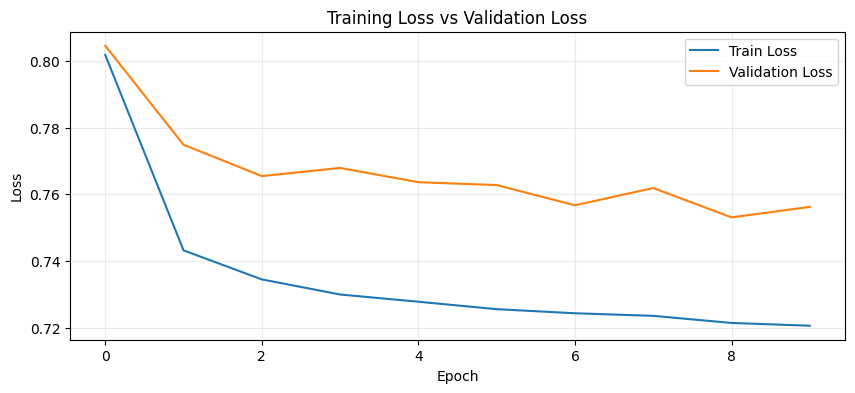

In [23]:
display(history_df.tail())

plt.figure(figsize=(10, 4))
plt.plot(history_df["train_loss"], label="Train Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

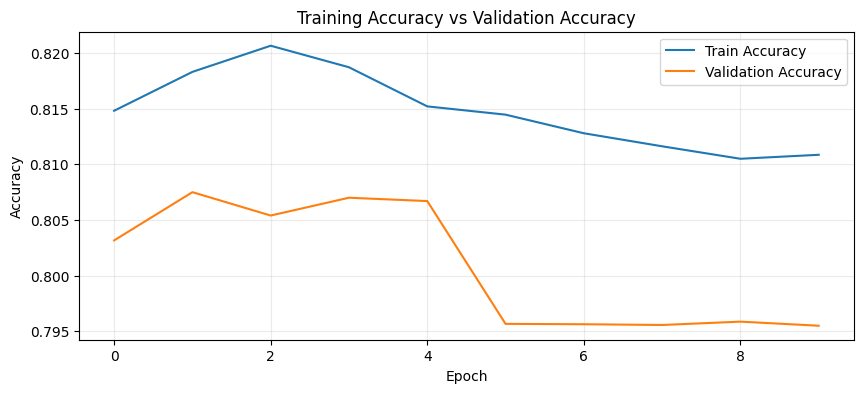

In [24]:
plt.figure(figsize=(10, 4))
plt.plot(history_df["train_accuracy"], label="Train Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
plt.title("Training Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 16. Predict

In [25]:
def predict_loader(
    model,
    loader
):
    model.eval()

    probs_all = []
    preds_all = []
    targets_all = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)

            logits = model(X_batch)

            probs = torch.softmax(
                logits,
                dim=1
            )

            preds = probs.argmax(dim=1)

            probs_all.append(
                probs.cpu().numpy()
            )

            preds_all.append(
                preds.cpu().numpy()
            )

            targets_all.append(
                y_batch.numpy()
            )

    return (
        np.concatenate(probs_all),
        np.concatenate(preds_all),
        np.concatenate(targets_all)
    )


y_prob, y_pred, y_true = predict_loader(
    model,
    test_loader
)

print("Số dự đoán:", len(y_pred))
print("10 nhãn thật:")
print([ID_TO_EVENT[int(i)] for i in y_true[:10]])

print("\n10 nhãn dự đoán:")
print([ID_TO_EVENT[int(i)] for i in y_pred[:10]])

Số dự đoán: 30000
10 nhãn thật:
['view', 'view', 'view', 'transaction', 'view', 'view', 'view', 'view', 'view', 'view']

10 nhãn dự đoán:
['view', 'view', 'view', 'transaction', 'addtocart', 'view', 'addtocart', 'view', 'view', 'view']


## 17. Evaluate

In [26]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy    = {accuracy:.4f}")
print(f"Macro F1    = {macro_f1:.4f}")
print(f"Weighted F1 = {weighted_f1:.4f}")

Accuracy    = 0.8146
Macro F1    = 0.5349
Weighted F1 = 0.8506


## 18. Confusion Matrix + Classification Report

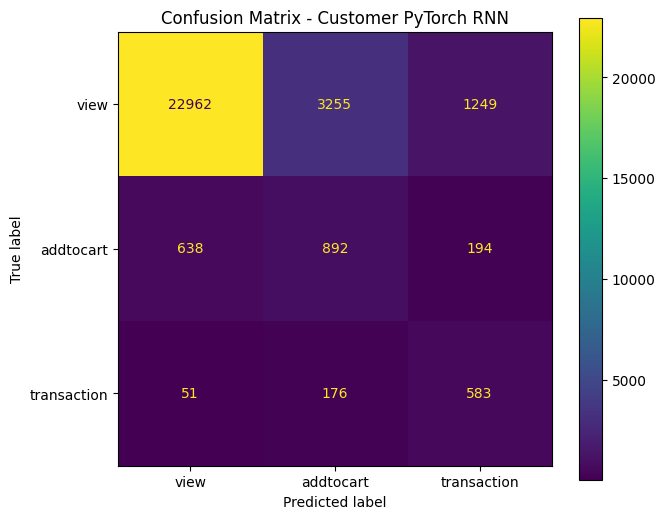

In [27]:
labels = [0, 1, 2]
display_labels = [
    "view",
    "addtocart",
    "transaction"
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format="d")
plt.title("Confusion Matrix - Customer PyTorch RNN")
plt.show()

In [28]:
report = classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=display_labels,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).T

display(report_df.round(4))

,precision,recall,f1-score,support
view,0.9709,0.8360,0.8984,27466.0000
addtocart,0.2063,0.5174,0.2950,1724.0000
transaction,0.2878,0.7198,0.4111,810.0000
accuracy,0.8146,0.8146,0.8146,0.8146
macro avg,0.4883,0.6911,0.5349,30000.0000
weighted avg,0.9085,0.8146,0.8506,30000.0000


## 19. Majority Baseline

In [29]:
def transition_baseline(X_train, y_train, X, n_classes=3, balance=False):
    """First-order Markov baseline fitted exclusively on train, with Laplace smoothing."""
    counts = np.ones((n_classes, n_classes), dtype=np.float64)
    np.add.at(counts, (X_train[:, -1], y_train), 1)
    probabilities = counts / counts.sum(axis=1, keepdims=True)
    if balance:
        frequencies = np.bincount(y_train, minlength=n_classes).clip(min=1)
        probabilities /= frequencies / frequencies.sum()
    return probabilities[X[:, -1]].argmax(axis=1)

majority_class = int(
    pd.Series(y_train)
      .value_counts()
      .idxmax()
)

baseline_pred = np.full(
    len(y_true),
    majority_class,
    dtype=np.int64
)

baseline_accuracy = accuracy_score(
    y_true,
    baseline_pred
)

baseline_macro_f1 = f1_score(
    y_true,
    baseline_pred,
    average="macro",
    zero_division=0
)

comparison_df = pd.DataFrame({
    "Model": [
        "PyTorch SimpleRNN",
        "Majority Baseline"
    ],
    "Accuracy": [
        accuracy,
        baseline_accuracy
    ],
    "Macro_F1": [
        macro_f1,
        baseline_macro_f1
    ]
})

display(comparison_df.round(4))
# Additional sequence-aware baselines, fitted on train only.
for name, prediction in [
    ("Last event", X_test[:, -1]),
    ("Markov", transition_baseline(X_train, y_train, X_test)),
    ("Balanced Markov", transition_baseline(X_train, y_train, X_test, balance=True)),
]:
    comparison_df.loc[len(comparison_df)] = [name, accuracy_score(y_test, prediction),
        f1_score(y_test, prediction, labels=[0, 1, 2], average="macro", zero_division=0)]
display(comparison_df.round(4))

,Model,Accuracy,Macro_F1
0,PyTorch SimpleRNN,0.8146,0.5349
1,Majority Baseline,0.9155,0.3186


,Model,Accuracy,Macro_F1
0,PyTorch SimpleRNN,0.8146,0.5349
1,Majority Baseline,0.9155,0.3186
2,Last event,0.8894,0.4818
3,Markov,0.9155,0.3186
4,Balanced Markov,0.8890,0.4408


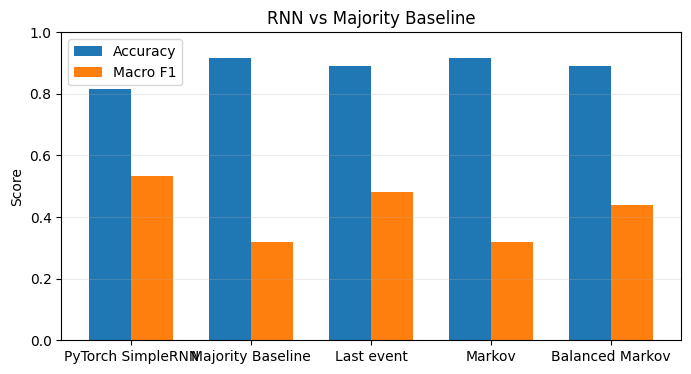

In [30]:
x = np.arange(len(comparison_df))
width = 0.35

plt.figure(figsize=(8, 4))

plt.bar(
    x - width/2,
    comparison_df["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width/2,
    comparison_df["Macro_F1"],
    width,
    label="Macro F1"
)

plt.xticks(x, comparison_df["Model"])
plt.ylim(0, 1)
plt.title("RNN vs Majority Baseline")
plt.ylabel("Score")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.show()

## 20. Actual vs Predicted Labels

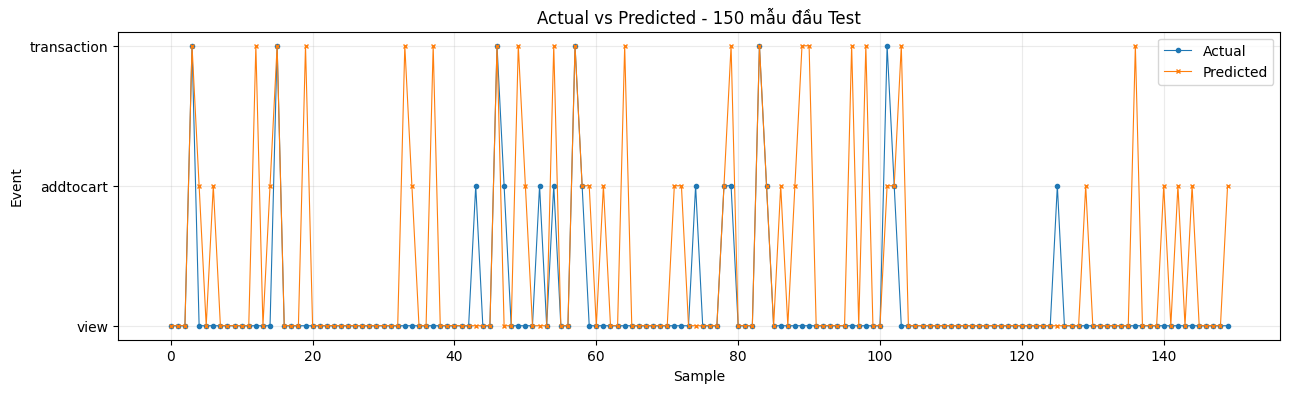

In [31]:
N_PLOT = min(150, len(y_true))

plt.figure(figsize=(15, 4))

plt.plot(
    np.arange(N_PLOT),
    y_true[:N_PLOT],
    marker="o",
    markersize=3,
    linewidth=0.8,
    label="Actual"
)

plt.plot(
    np.arange(N_PLOT),
    y_pred[:N_PLOT],
    marker="x",
    markersize=3,
    linewidth=0.8,
    label="Predicted"
)

plt.yticks(
    [0, 1, 2],
    ["view", "addtocart", "transaction"]
)

plt.title(
    f"Actual vs Predicted - {N_PLOT} mẫu đầu Test"
)

plt.xlabel("Sample")
plt.ylabel("Event")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 21. Demo dự đoán

In [32]:
def predict_next_event(event_sequence):
    if len(event_sequence) != SEQ_LENGTH:
        raise ValueError(
            f"Cần đúng {SEQ_LENGTH} event."
        )

    encoded = np.array(
        [EVENT_TO_ID[event] for event in event_sequence],
        dtype=np.int64
    )

    X_demo = torch.tensor(
        encoded,
        dtype=torch.long
    ).unsqueeze(0).to(DEVICE)

    model.eval()

    with torch.no_grad():
        logits = model(X_demo)
        probs = torch.softmax(
            logits,
            dim=1
        )[0].cpu().numpy()

    pred_id = int(np.argmax(probs))

    result = pd.DataFrame({
        "event": [
            ID_TO_EVENT[i]
            for i in range(NUM_EVENTS)
        ],
        "probability": probs
    }).sort_values(
        "probability",
        ascending=False
    )

    print(
        "Input:",
        " -> ".join(event_sequence)
    )

    print(
        "Predicted next event:",
        ID_TO_EVENT[pred_id]
    )

    display(result.reset_index(drop=True))


demo_sequence = [
    "view",
    "view",
    "view",
    "addtocart",
    "view"
]

predict_next_event(demo_sequence)

Input: view -> view -> view -> addtocart -> view
Predicted next event: addtocart


,event,probability
0,addtocart,0.529620
1,transaction,0.362895
2,view,0.107484


## 22. Lưu model và kết quả

In [33]:
import hashlib
import importlib.metadata

def save_metadata(path, *, task, framework, seed, seq_length, dataset, **extra):
    digest = hashlib.sha256()
    with Path(dataset).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    versions = {}
    for name in ("numpy", "pandas", "scikit-learn", "tensorflow", "keras", "torch"):
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            pass
    metadata = dict(schema_version=1, task=task, framework=framework, seed=seed,
                    seq_length=seq_length, dataset_sha256=digest.hexdigest(),
                    package_versions=versions, **extra)
    Path(path).write_text(json.dumps(metadata, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    return metadata

test_result_df = pd.DataFrame({
    "target_time": time_test.reset_index(drop=True),
    "actual_event": [
        ID_TO_EVENT[int(i)]
        for i in y_true
    ],
    "predicted_event": [
        ID_TO_EVENT[int(i)]
        for i in y_pred
    ],
    "prob_view": y_prob[:, EVENT_TO_ID["view"]],
    "prob_addtocart": y_prob[:, EVENT_TO_ID["addtocart"]],
    "prob_transaction": y_prob[:, EVENT_TO_ID["transaction"]]
})

prediction_path = (
    RESULTS_DIR
    / "Customer_PyTorch_predictions.csv"
)

test_result_df.to_csv(
    prediction_path,
    index=False
)

model_path = (
    RESULTS_DIR
    / "Customer_PyTorch_SimpleRNN.pth"
)

torch.save({"model_state_dict": model.state_dict()}, model_path)

print("Predictions:", prediction_path)
print("Model:", model_path)

display(test_result_df.head())
metadata_extra = dict(**selected_config, selection_metric='val_macro_f1',
    train_samples=len(X_train), validation_samples=len(X_val), test_samples=len(X_test))

metadata_extra.update(architecture="embedding_simple_rnn", event_to_id=EVENT_TO_ID,
    probability_calibrated=False, strict_past_events=True,
    split_dates={"train_end": str(time_train.max()), "val_start": str(time_val.min()),
                 "val_end": str(time_val.max()), "test_start": str(time_test.min())},
    test_metrics={"accuracy": float(accuracy), "macro_f1": float(macro_f1), "weighted_f1": float(weighted_f1)})
comparison_df.to_csv(RESULTS_DIR / "Customer_PyTorch_metrics.csv", index=False)
report_df.to_csv(RESULTS_DIR / "Customer_PyTorch_classification_report.csv")

save_metadata(model_path.with_suffix(".json"), task="customer", framework="pytorch",
              seed=SEED, seq_length=SEQ_LENGTH, dataset=DATA_PATH, **metadata_extra)
history_df.to_csv(RESULTS_DIR / "Customer_PyTorch_history.csv", index=False)

Predictions: D:\A06\results\Customer_PyTorch_predictions.csv
Model: D:\A06\results\Customer_PyTorch_SimpleRNN.pth


,target_time,actual_event,predicted_event,prob_view,prob_addtocart,prob_transaction
0,2015-08-24 21:46:06.192,view,view,0.701372,0.275829,0.022799
1,2015-08-24 21:46:22.480,view,view,0.701372,0.275829,0.022799
2,2015-08-24 21:46:56.058,view,view,0.701372,0.275829,0.022799
3,2015-08-24 21:47:12.212,transaction,transaction,0.054160,0.114560,0.831280
4,2015-08-24 21:47:53.757,view,addtocart,0.107484,0.529620,0.362895


## 23. Kết luận

In [34]:
print("===== KẾT QUẢ CUỐI =====")
print(f"Sequence length  : {SEQ_LENGTH} event")
print(f"Train samples    : {len(X_train):,}")
print(f"Validation       : {len(X_val):,}")
print(f"Test samples     : {len(X_test):,}")
print()
print(f"RNN Accuracy     : {accuracy:.4f}")
print(f"RNN Macro F1     : {macro_f1:.4f}")
print(f"RNN Weighted F1  : {weighted_f1:.4f}")
print()
print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Macro F1: {baseline_macro_f1:.4f}")

===== KẾT QUẢ CUỐI =====
Sequence length  : 5 event
Train samples    : 140,000
Validation       : 30,000
Test samples     : 30,000

RNN Accuracy     : 0.8146
RNN Macro F1     : 0.5349
RNN Weighted F1  : 0.8506

Baseline Accuracy: 0.9155
Baseline Macro F1: 0.3186


### Cách diễn giải kết quả

- Mỗi mẫu dùng 5 event trước thời điểm target của cùng một visitor.
- Chia Train/Validation/Test theo thời gian; class weight chỉ tính từ Train.
- Chọn checkpoint bằng Validation Macro F1. Bản gốc trước cải tiến dùng
  validation loss, không phải chọn checkpoint bằng Test.
- Đọc Macro F1, precision/recall từng lớp và các baseline cùng với Accuracy.
- Tập Test này đã thay đổi so với bản gốc do loại target đồng thời và lấy mẫu lại.
  Không dùng chênh lệch điểm trước/sau để khẳng định model mới tốt hơn.
- Kết quả dành cho visitor có đủ lịch sử, không phải đánh giá cold-start.
- Điểm softmax sau class weighting chưa được calibration.

In [35]:
# Tải lại trực tiếp bằng framework và JSON; không cần file Python ngoài.
saved_metadata = json.loads(model_path.with_suffix(".json").read_text(encoding="utf-8"))
loaded_model = CustomerRNN(num_events=len(saved_metadata["event_to_id"]),
                           embed_dim=saved_metadata["embed_dim"], hidden_size=saved_metadata["hidden_size"],
                           num_classes=len(saved_metadata["event_to_id"]))

checkpoint = torch.load(model_path, map_location="cpu", weights_only=True)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

def predict_saved_events(event_windows):
    names = np.asarray(event_windows)
    if names.ndim == 1:
        names = names[None, :]
    if names.ndim != 2 or names.shape[1] != saved_metadata["seq_length"]:
        raise ValueError("Expected event windows with the saved sequence length")
    mapping = saved_metadata["event_to_id"]
    if any(str(event) not in mapping for event in names.flat):
        raise ValueError(f"Supported events: {list(mapping)}")
    values = np.array([[mapping[str(event)] for event in row] for row in names], dtype=np.int64)
    with torch.no_grad():
        return torch.softmax(loaded_model(torch.from_numpy(values)), dim=1).numpy()

named_windows = [[ID_TO_EVENT[int(v)] for v in row] for row in X_test[:64]]
np.testing.assert_allclose(predict_saved_events(named_windows), y_prob[:64], rtol=1e-5, atol=1e-6)
print("PASS: reloaded model + label mapping reproduce test predictions.")

PASS: reloaded model + label mapping reproduce test predictions.
